## Part A — Forward diffusion

For $X_0\sim\rho_0$, consider

$$dX_t=-\tfrac12 X_t\,dt+dW_t,\qquad 0\le t\le T.$$

The exact transition is

$$X_t=a_tX_0+\sigma_t Z,\quad a_t=e^{-t/2},\quad \sigma_t=\sqrt{1-e^{-t}},\quad Z\sim\mathcal N(0,I).$$

Hence $X_t\mid X_0=x_0\sim\mathcal N(a_tx_0,\sigma_t^2 I)$, and $X_t\Rightarrow\mathcal N(0,I)$ as $t\to\infty$. We simulate $X_t$ directly using the exact transition rather than discretizing the forward SDE.

Device: cuda


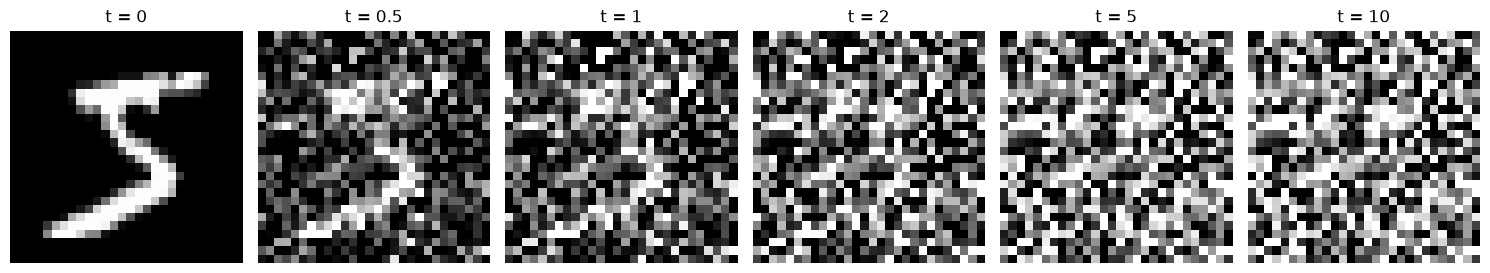

In [13]:

import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

x0, label = train_data[0]
x0 = x0.unsqueeze(0).to(device)

times = [0, 0.5, 1, 2, 5, 10]

# Use the same Gaussian noise for visualization.
z = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(times), figsize=(15, 3))

for ax, t in zip(axes, times):
    a = torch.exp(torch.tensor(-t / 2, device=device))
    sigma = torch.sqrt(
        torch.clamp(1 - torch.exp(torch.tensor(-t, device=device)),
                    min=0)
    )
    xt = a * x0 + sigma * z

    image = ((xt[0, 0].cpu() + 1) / 2).clamp(0, 1)
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Part 2

In [14]:
T = 10.0
T_MIN = 1e-3

def diffusion_coefficients(t):
    """
    t: Tensor of shape [B]
    Returns coefficients broadcastable to [B, 1, 28, 28].
    """
    t = t.reshape(-1, 1, 1, 1)
    a = torch.exp(-0.5 * t)
    sigma = torch.sqrt(-torch.expm1(-t))
    return a, sigma


def make_training_batch(x0):
    """
    x0: Clean MNIST images, shape [B, 1, 28, 28].
    Values normalized to [-1, 1].

    Returns:
        xt: Noisy images
        t: Diffusion times
        z: Gaussian noise targets
    """
    B = x0.shape[0]
    device = x0.device

    t = T_MIN + (T - T_MIN) * torch.rand(
        B, device=device
    )

    z = torch.randn_like(x0)

    a, sigma = diffusion_coefficients(t)

    xt = a * x0 + sigma * z

    return xt, t, z


Part 3

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(
            torch.arange(
                half, device=t.device, dtype=t.dtype
            ) * (-math.log(10000) / (half - 1))
        )
        angles = t[:, None] * freqs[None, :]
        return torch.cat(
            [torch.sin(angles), torch.cos(angles)], dim=1
        )


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim=64):
        super().__init__()

        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)

        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)

        self.time_proj = nn.Linear(time_dim, out_ch)

        self.skip = (
            nn.Conv2d(in_ch, out_ch, 1)
            if in_ch != out_ch else nn.Identity()
        )

    def forward(self, x, temb):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time_proj(temb)[:, :, None, None]
        h = F.silu(self.norm2(self.conv2(h)))
        return h + self.skip(x)


class SmallUNet(nn.Module):
    def __init__(self, base=32, time_dim=64):
        super().__init__()

        self.time_embed = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.enc1 = ResBlock(1, base, time_dim)
        self.down1 = nn.Conv2d(base, base, 3, 2, 1)

        self.enc2 = ResBlock(base, base * 2, time_dim)
        self.down2 = nn.Conv2d(base * 2, base * 2, 3, 2, 1)

        self.middle = ResBlock(
            base * 2, base * 2, time_dim
        )

        self.dec2 = ResBlock(
            base * 4, base * 2, time_dim
        )
        self.dec1 = ResBlock(
            base * 3, base, time_dim
        )

        self.out = nn.Conv2d(base, 1, 3, padding=1)

    def forward(self, x, t):
        temb = self.time_embed(t)

        e1 = self.enc1(x, temb)       # 28 x 28
        e2 = self.enc2(
            self.down1(e1), temb
        )                             # 14 x 14

        h = self.middle(
            self.down2(e2), temb
        )                             # 7 x 7

        h = F.interpolate(
            h, size=e2.shape[-2:], mode="nearest"
        )
        h = self.dec2(
            torch.cat([h, e2], dim=1), temb
        )

        h = F.interpolate(
            h, size=e1.shape[-2:], mode="nearest"
        )
        h = self.dec1(
            torch.cat([h, e1], dim=1), temb
        )

        return self.out(h)

Part 4

Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1: loss = 0.05269


Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2: loss = 0.01810


Epoch 3/20:   0%|          | 0/469 [00:00<?, ?it/s]

...

Epoch 18: loss = 0.01005


Epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 19: loss = 0.00990


Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 20: loss = 0.00981


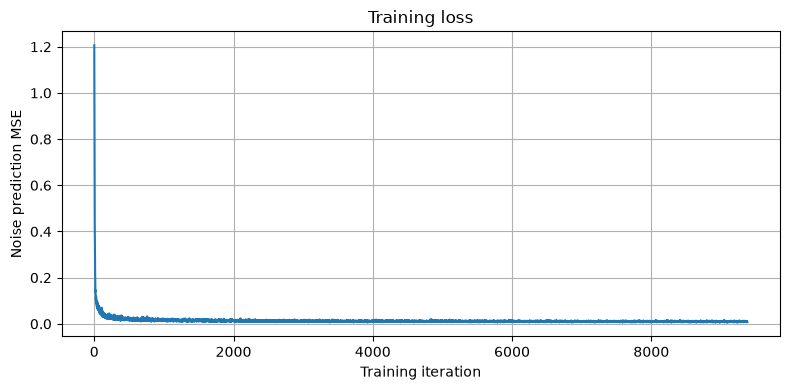

In [16]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

USE_CUDA = device.type == "cuda"

BASE_CHANNELS = 32 if USE_CUDA else 16
BATCH_SIZE = 128 if USE_CUDA else 64
EPOCHS = 20 if USE_CUDA else 5
MAX_IMAGES = 60000 if USE_CUDA else 10000
LEARNING_RATE = 2e-4

os.makedirs("diffusion_outputs", exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

if MAX_IMAGES < len(dataset):
    dataset = Subset(dataset, range(MAX_IMAGES))

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=USE_CUDA
)

model = SmallUNet(base=BASE_CHANNELS).to(device)
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE
)

loss_history = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0

    progress = tqdm(loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for x0, _ in progress:
        x0 = x0.to(device)

        xt, t, z = make_training_batch(x0)

        z_pred = model(xt, t)
        loss = F.mse_loss(z_pred, z)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        loss_history.append(loss.item())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    print(
        f"Epoch {epoch+1}: "
        f"loss = {epoch_loss / len(loader):.5f}"
    )

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "base_channels": BASE_CHANNELS,
        "epochs": EPOCHS
    },
    "diffusion_outputs/mnist_score_model.pt"
)

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Training iteration")
plt.ylabel("Noise prediction MSE")
plt.title("Training loss")
plt.grid(True)
plt.tight_layout()
plt.savefig("diffusion_outputs/training_loss.png", dpi=150)
plt.show()


Part

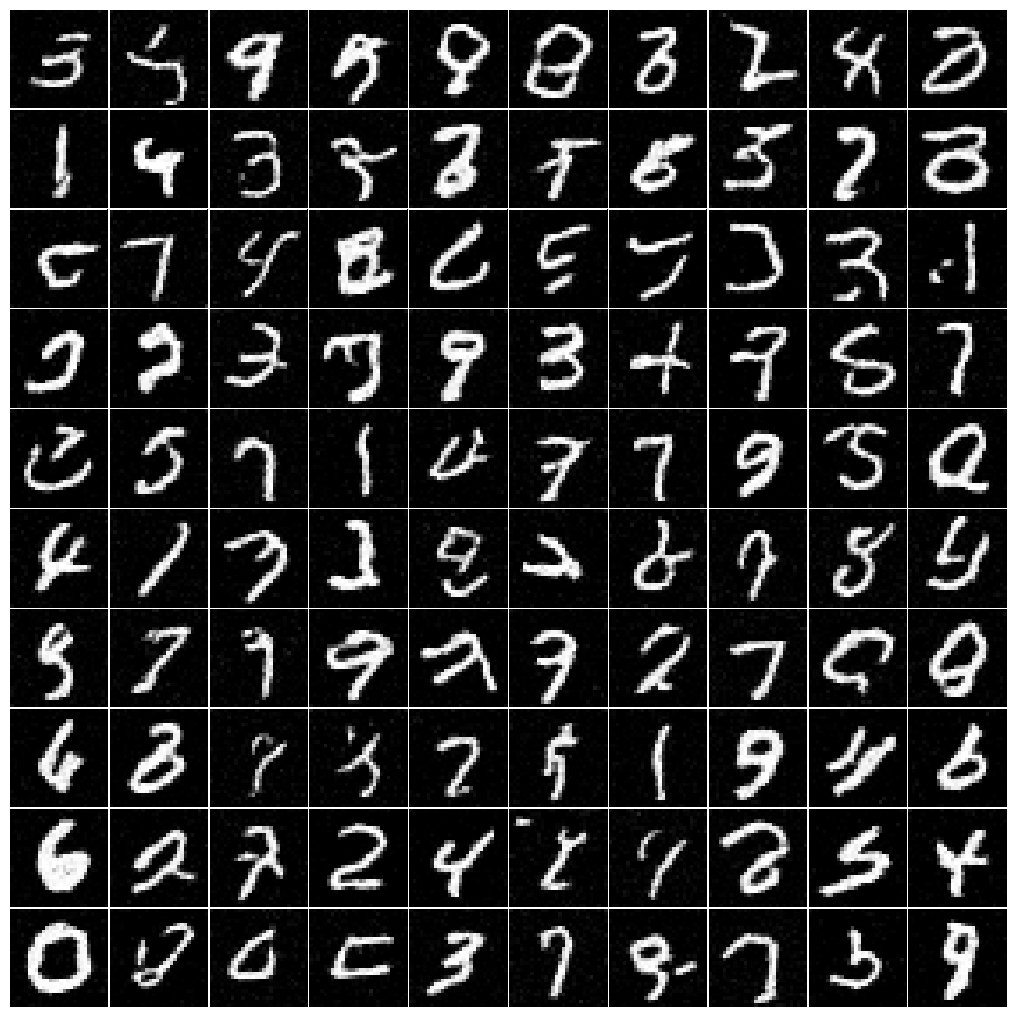

In [17]:

import numpy as np
import matplotlib.pyplot as plt

@torch.no_grad()
def generate_images(
    model,
    num_images=100,
    num_steps=500,
    T=10.0,
    t_min=1e-3,
    device=device,
    save_times=None
):
    model.eval()

    x = torch.randn(
        num_images, 1, 28, 28, device=device
    )

    times = torch.linspace(
        T, t_min, num_steps + 1, device=device
    )

    snapshots = {}

    if save_times is not None:
        snapshots[T] = x.detach().cpu().clone()

    for k in range(num_steps):
        t_now = times[k]
        h = (times[k] - times[k + 1]).item()

        t_batch = torch.full(
            (num_images,),
            t_now.item(),
            device=device
        )

        _, sigma = diffusion_coefficients(t_batch)

        eps_pred = model(x, t_batch)
        score = -eps_pred / sigma

        drift = 0.5 * x + score

        noise = (
            torch.randn_like(x)
            if k < num_steps - 1
            else torch.zeros_like(x)
        )

        x = x + drift * h + np.sqrt(h) * noise

        if save_times is not None:
            for target in save_times:
                if (
                    target not in snapshots
                    and times[k + 1].item() <= target
                ):
                    snapshots[target] = (
                        x.detach().cpu().clone()
                    )

    return x.detach().cpu(), snapshots


samples, snapshots = generate_images(
    model,
    num_images=100,
    num_steps=500 if USE_CUDA else 150,
    save_times=[10, 5, 2, 1, 0.5, 1e-3]
)

fig, axes = plt.subplots(10, 10, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    image = ((samples[i, 0] + 1) / 2).clamp(0, 1)

    ax.imshow(
        image.numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.tight_layout(pad=0.1)
plt.savefig(
    "diffusion_outputs/generated_digits.png",
    dpi=200
)
plt.show()


Part

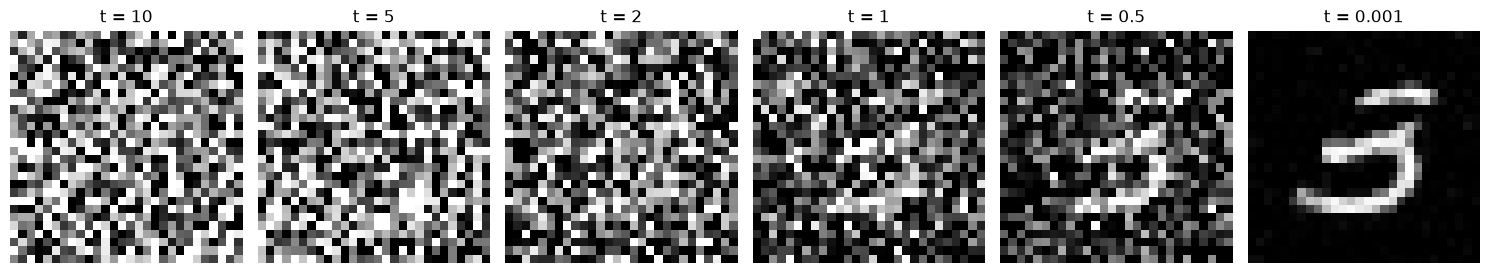

In [18]:
display_times = [10, 5, 2, 1, 0.5, 1e-3]

# Ensure the final snapshot exists
snapshots[1e-3] = samples.clone()

fig, axes = plt.subplots(
    1, len(display_times), figsize=(15, 3)
)

for ax, t in zip(axes, display_times):
    image = snapshots[t][0, 0]

    display_image = (
        (image + 1) / 2
    ).clamp(0, 1)

    ax.imshow(
        display_image.numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"t = {t:g}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "diffusion_outputs/reverse_trajectory.png",
    dpi=150
)
plt.show()